# Volatility Risk Premia in CME G10 FX Options on Futures
### Analysis notebook

Nicholas Hong, Nanyang Technological University

This notebook reproduces every headline table and figure of the paper from the
option-level VRP panel (`clean_v3/vrp_v3/vrp_panel_v3.parquet`, output of
pipeline step 10). It covers: the daily panel aggregation (step 11), leak-free
strategy payoff proxies (step 12), robust inference (step 13), and all charts
and tables (step 14).

**Wording note:** all strategy results are payoff proxies (ex-post implied
minus forward realized volatility of selected positions), not executable P&L.
Transaction costs, delta hedging, and margin are excluded.

**Data prerequisites:** the pipeline through step 10 must have been run; see
`README.md` and `scripts/00_inventory.py` .. `scripts/10_vrp.py`.

In [1]:
import os
import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt

WORK = os.path.abspath(os.path.join(os.getcwd(), ".."))
VD = os.path.join(WORK, "clean_v3", "vrp_v3")
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.grid": True,
                     "grid.alpha": 0.3, "axes.axisbelow": True})
ROOT_COLORS = {"6A": "#1f77b4", "6B": "#ff7f0e", "6C": "#2ca02c",
               "6E": "#d62728", "6J": "#9467bd", "6N": "#8c564b",
               "6S": "#17becf"}
ROOT_NAMES = {"6A": "AUD", "6B": "GBP", "6C": "CAD", "6E": "EUR",
              "6J": "JPY", "6N": "NZD", "6S": "CHF"}
ROOTS = list(ROOT_COLORS)

## 1. Load the option-level VRP panel (step 10 output)

Each row is one selected near-ATM option on one date, with Black-76 implied
volatility and the forward realized volatility of its own underlying futures
contract over the matching tenor horizon.

In [2]:
panel = pd.read_parquet(os.path.join(VD, "vrp_panel_v3.parquet"))
print(f"rows: {len(panel):,}   dates: {panel.date.min().date()} .. {panel.date.max().date()}")
print(panel.rv_status.value_counts().to_dict())
panel.head(3)

rows: 430,630   dates: 2010-06-04 .. 2026-06-26
{'ok': 427774, 'short_span': 2730, 'no_data': 126}


,date,instrument_id,raw_symbol,asset,economic_root,option_type,strike_price,expiration,option_settle,open_interest,...,iv_model_abs_err,rv_sum_r2,rv_n_returns,rv_span_days,rv_status,realized_vol,realized_var,implied_var,vrp_var,vrp_vol_spread
0,2010-06-04,677744,6AN0 C0810,6A,6A,C,0.810,2010-07-09 19:00:00+00:00,0.0200,NaN,...,1.734723e-17,0.002026,20,28.0,ok,0.159782,0.02553,0.036337,0.010806,0.030840
1,2010-06-04,553283,6AN0 C0815,6A,6A,C,0.815,2010-07-09 19:00:00+00:00,0.0173,NaN,...,3.816392e-17,0.002026,20,28.0,ok,0.159782,0.02553,0.035250,0.009719,0.027966
2,2010-06-04,395762,6AN0 C0805,6A,6A,C,0.805,2010-07-09 19:00:00+00:00,0.0230,NaN,...,9.020562e-17,0.002026,20,28.0,ok,0.159782,0.02553,0.037816,0.012285,0.034680


## 2. Daily panel (step 11)

Keep `rv_status == 'ok'` rows, apply the 6N anomaly exclusion (6N enters
2014-01-01; the structurally suspicious legacy 6N IV regime of 30-40% prints
on zero-open-interest contracts persists through 2013), and aggregate
equal-weight to (date, root, tenor).

In [3]:
ok = panel[panel.rv_status == "ok"]
ok = ok[~((ok.economic_root == "6N") & (ok.date < "2014-01-01"))]
daily = (ok.groupby(["date", "economic_root", "target_tenor"], as_index=False)
           .agg(black76_iv=("black76_iv", "mean"),
                realized_vol=("realized_vol", "mean"),
                vrp_vol_spread=("vrp_vol_spread", "mean"),
                open_interest=("open_interest", "sum")))
daily = daily.sort_values(["economic_root", "target_tenor", "date"]).reset_index(drop=True)
print(f"daily panel rows: {len(daily):,}")

daily panel rows: 70,714


## 3. Table 1 and Table 2: the premium by root and tenor

In [4]:
t1 = (daily.groupby("economic_root")[["black76_iv", "realized_vol", "vrp_vol_spread"]]
       .median() * 100).round(2)
t1.columns = ["median_iv", "median_rv", "median_vrp_spread"]
t1

,median_iv,median_rv,median_vrp_spread
economic_root,,,
6A,9.84,9.36,0.56
6B,7.98,7.78,0.64
6C,7.00,6.68,0.53
6E,7.55,7.30,0.51
6J,9.07,8.21,0.87
6N,9.33,9.81,-0.03
6S,7.71,7.44,0.39


In [5]:
t2 = daily.groupby("target_tenor").agg(
    median_vrp_spread=("vrp_vol_spread", lambda s: round(100 * s.median(), 2)),
    positive_pct=("vrp_vol_spread", lambda s: round(100 * (s > 0).mean(), 1)),
    n_obs=("vrp_vol_spread", "size"))
t2

,median_vrp_spread,positive_pct,n_obs
target_tenor,,,
30,0.57,62.5,25336
60,0.50,62.4,24185
90,0.49,62.7,21193


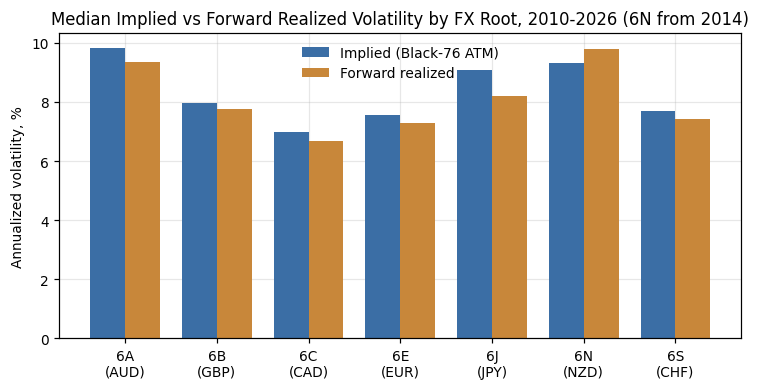

In [6]:
x = np.arange(len(ROOTS)); w = 0.38
lab = [f"{r}\n({ROOT_NAMES[r]})" for r in ROOTS]
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(x - w/2, t1.median_iv, w, label="Implied (Black-76 ATM)", color="#3b6ea5")
ax.bar(x + w/2, t1.median_rv, w, label="Forward realized", color="#c8873a")
ax.set_xticks(x, lab); ax.set_ylabel("Annualized volatility, %")
ax.set_title("Median Implied vs Forward Realized Volatility by FX Root, 2010-2026 (6N from 2014)")
ax.legend(frameon=False); plt.show()

JPY carries the widest gap (0.87 vol points at the median);
NZD is the one root where realized exceeds implied. The premium is slightly
stronger at the short end across tenors.

## 4. Yearly regimes

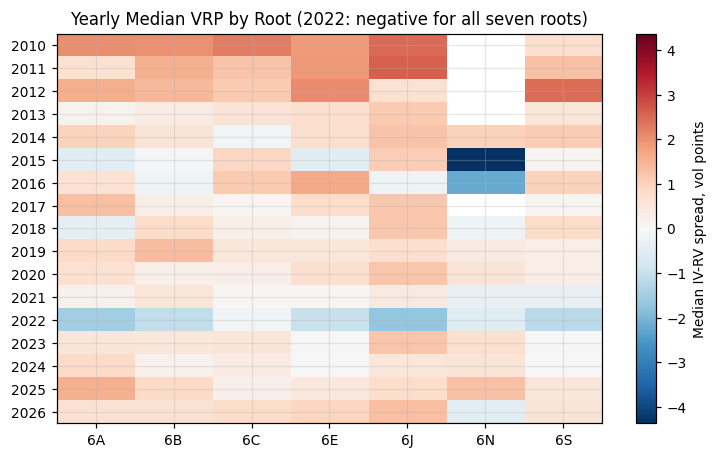

economic_root,6A,6B,6C,6E,6J,6N,6S
year,,,,,,,
2015,-0.49,-0.07,0.89,-0.45,1.07,-4.37,0.13
2020,0.66,0.23,0.28,0.70,1.21,0.56,0.30
2022,-1.53,-1.06,-0.12,-0.99,-1.69,-0.53,-1.17
2025,1.56,0.83,0.22,0.46,0.76,1.28,0.51


In [7]:
daily["year"] = daily.date.dt.year
t4 = (daily.pivot_table(index="year", columns="economic_root",
                        values="vrp_vol_spread", aggfunc="median") * 100).round(2)
vmax = np.nanmax(np.abs(t4.values))
fig, ax = plt.subplots(figsize=(8, 4.6))
im = ax.imshow(t4.values, aspect="auto", cmap="RdBu_r", vmin=-vmax, vmax=vmax)
ax.set_xticks(range(len(t4.columns)), t4.columns)
ax.set_yticks(range(len(t4)), t4.index)
fig.colorbar(im, ax=ax, label="Median IV-RV spread, vol points")
ax.set_title("Yearly Median VRP by Root (2022: negative for all seven roots)")
plt.show()
t4.loc[[2015, 2020, 2022, 2025]]

## 5. Strategy payoff proxies (step 12)

Twelve variants in three families. The conditioning signal is a leak-free
implied-volatility z-score: per root-tenor, the rolling mean and standard
deviation of the trailing 252 observations ending at t-1 (series shifted one
day before the rolling statistics), minimum 126 observations.

In [8]:
d = daily.sort_values(["economic_root", "target_tenor", "date"]).copy()
g = d.groupby(["economic_root", "target_tenor"], group_keys=False)
d["iv_z"] = (d.black76_iv - g.black76_iv.apply(
    lambda s: s.shift(1).rolling(252, min_periods=126).mean())) / \
    g.black76_iv.apply(lambda s: s.shift(1).rolling(252, min_periods=126).std())

def daily_series(sel, name):
    s = sel.groupby("date")["vrp_vol_spread"].mean().rename("payoff").reset_index()
    s["strategy"] = name
    return s

MAJORS = ["6E", "6B", "6J", "6S"]
series = [daily_series(d, "static_all_roots_all_tenors")]
for t in (30, 60, 90):
    series.append(daily_series(d[d.target_tenor == t], f"static_{t}d"))
series.append(daily_series(d[d.economic_root != "6N"], "static_ex_6N"))
series.append(daily_series(d[d.economic_root.isin(MAJORS)], "static_major_roots_only"))
dz = d[d.iv_z.notna()]
for thr, tag in ((0.0, "ge_0"), (0.5, "ge_0p5"), (1.0, "ge_1")):
    series.append(daily_series(dz[dz.iv_z >= thr], f"signal_iv_zscore_{tag}"))
for n in (1, 2, 3):
    top = (dz.sort_values("iv_z", ascending=False)
             .groupby(["date", "target_tenor"], group_keys=False).head(n))
    series.append(daily_series(top, f"xs_top{n}_iv_z_by_date_tenor"))
allp = pd.concat(series, ignore_index=True)
allp["payoff_volpts"] = allp.payoff * 100
print(f"strategies: {allp.strategy.nunique()},  strategy-days: {len(allp):,}")

strategies: 12,  strategy-days: 40,887


## 6. Robust inference (step 13)

Forward RV windows overlap across consecutive dates, so naive t-statistics
are badly inflated. Two treatments: Newey-West HAC t-statistics at lags
5/21/63 (63 = one quarter, matching the longest RV horizon, is the headline),
and non-overlapping sampling (every 21st observation at all 21 offsets,
simple t per offset, averaged).

In [9]:
def nw_t(y, lag):
    res = sm.OLS(np.asarray(y, float), np.ones((len(y), 1))).fit(
        cov_type="HAC", cov_kwds={"maxlags": lag})
    return float(res.tvalues[0])

def nonoverlap_t(y, step=21):
    y = np.asarray(y, float)
    ts = [s.mean() / (s.std(ddof=1) / np.sqrt(len(s)))
          for off in range(step)
          for s in [y[off::step]] if len(s) > 10 and s.std(ddof=1) > 0]
    return float(np.mean(ts))

rows = []
for strat, gg in allp.groupby("strategy"):
    y = gg.sort_values("date").payoff_volpts.to_numpy()
    rows.append({"strategy": strat, "n_days": len(y), "mean": y.mean(),
                 "median": np.median(y), "positive_pct": 100 * (y > 0).mean(),
                 "skew": pd.Series(y).skew(), "ex_kurt": pd.Series(y).kurt(),
                 "t_nw5": nw_t(y, 5), "t_nw63": nw_t(y, 63),
                 "t_nonoverlap21": nonoverlap_t(y)})
ORDER = ["static_all_roots_all_tenors", "static_30d", "static_60d", "static_90d",
         "static_ex_6N", "static_major_roots_only", "signal_iv_zscore_ge_0",
         "signal_iv_zscore_ge_0p5", "signal_iv_zscore_ge_1",
         "xs_top1_iv_z_by_date_tenor", "xs_top2_iv_z_by_date_tenor",
         "xs_top3_iv_z_by_date_tenor"]
t3 = pd.DataFrame(rows).set_index("strategy").loc[ORDER].round(3)
t3

,n_days,mean,median,positive_pct,skew,ex_kurt,t_nw5,t_nw63,t_nonoverlap21
strategy,,,,,,,,,
static_all_roots_all_tenors,3991,0.277,0.492,65.598,-1.689,6.998,4.388,1.791,2.268
static_30d,3808,0.306,0.530,65.914,-2.212,11.444,4.579,2.399,2.320
static_60d,3657,0.206,0.424,63.659,-1.745,7.075,2.926,1.230,1.519
static_90d,3191,0.162,0.391,60.984,-1.481,5.027,2.087,0.824,1.094
static_ex_6N,3991,0.340,0.570,68.078,-1.810,7.411,5.376,2.209,2.774
static_major_roots_only,3991,0.319,0.618,67.176,-1.882,7.484,4.619,1.934,2.376
signal_iv_zscore_ge_0,2785,0.385,0.645,65.889,-1.836,9.294,3.912,1.806,1.985
signal_iv_zscore_ge_0p5,2215,0.378,0.647,64.560,-1.729,8.552,3.082,1.503,1.526
signal_iv_zscore_ge_1,1675,0.275,0.620,61.313,-1.615,7.484,1.784,0.941,0.916


Reading the table: the static premium is positive but marginal
(NW63 t = 1.79); cross-sectional top-1 high-IV selection nearly doubles the
mean (0.51 vs 0.28 vol points, NW63 t = 2.41) with monotone attenuation
through top-2 and top-3; the time-series threshold family adds little once the
z-score is leak-free. Skewness is negative in every variant: the premium is
compensation for a left tail, realized broadly in 2022. The headline
conditional rule is the best of twelve variants, so its significance should be
discounted for specification search.

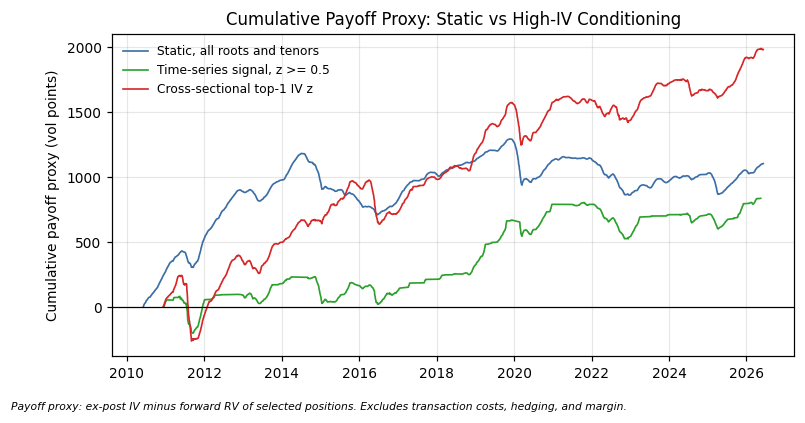

In [10]:
fig, ax = plt.subplots(figsize=(8, 3.8))
for s, c, l in [("static_all_roots_all_tenors", "#3b6ea5", "Static, all roots and tenors"),
                ("signal_iv_zscore_ge_0p5", "#2ca02c", "Time-series signal, z >= 0.5"),
                ("xs_top1_iv_z_by_date_tenor", "#d62728", "Cross-sectional top-1 IV z")]:
    gg = allp[allp.strategy == s].sort_values("date")
    ax.plot(gg.date, gg.payoff_volpts.cumsum(), color=c, lw=1.1, label=l)
ax.axhline(0, color="k", lw=0.8)
ax.set_ylabel("Cumulative payoff proxy (vol points)")
ax.set_title("Cumulative Payoff Proxy: Static vs High-IV Conditioning")
ax.legend(frameon=False, fontsize=8)
fig.text(0.01, -0.02, "Payoff proxy: ex-post IV minus forward RV of selected positions. "
         "Excludes transaction costs, hedging, and margin.", fontsize=7, style="italic")
plt.show()

## 7. Consistency check against the pipeline outputs

The notebook recomputation must match the step 12/13 CSV outputs exactly.

In [11]:
ref = pd.read_csv(os.path.join(VD, "robust_stats_step13",
                                "robust_strategy_summary_v3.csv"), index_col=0)
chk = t3.join(ref[["mean", "t_nw63"]], rsuffix="_ref")
chk["mean_match"] = np.isclose(chk["mean"], chk["mean_ref"], atol=5e-4)
chk["t_match"] = np.isclose(chk["t_nw63"], chk["t_nw63_ref"], atol=5e-3)
assert chk.mean_match.all() and chk.t_match.all(), "MISMATCH vs pipeline outputs"
print("All 12 strategies match the pipeline outputs (mean and NW63 t).")
chk[["mean", "mean_ref", "t_nw63", "t_nw63_ref"]]

All 12 strategies match the pipeline outputs (mean and NW63 t).


,mean,mean_ref,t_nw63,t_nw63_ref
strategy,,,,
static_all_roots_all_tenors,0.277,0.2766,1.791,1.7906
static_30d,0.306,0.3063,2.399,2.3990
static_60d,0.206,0.2062,1.230,1.2303
static_90d,0.162,0.1619,0.824,0.8244
static_ex_6N,0.340,0.3404,2.209,2.2090
static_major_roots_only,0.319,0.3188,1.934,1.9344
signal_iv_zscore_ge_0,0.385,0.3847,1.806,1.8063
signal_iv_zscore_ge_0p5,0.378,0.3781,1.503,1.5027
signal_iv_zscore_ge_1,0.275,0.2754,0.941,0.9411
